# K-Means hyperparameter optimization

## 1 Setup and data

In [610]:
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             calinski_harabasz_score)
import os
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

RANDOM_STATE = 42
IMG_DIR = "figs/tuned"
MODEL_DIR = "model"
os.makedirs(IMG_DIR, exist_ok=True)
os.makedirs(MODEL_DIR, exist_ok=True)
pd.set_option("display.max_columns", None)

deepgreen = "#1d6c61"
verdigris = "#3e89ab"
red = "#c4515a"
COLORS = [deepgreen, verdigris, "#d08c3a", "#8a5aa3", "#5aa371", red]
plt.rcParams.update({"axes.grid": True, "grid.color": "#e6eeeb", "axes.axisbelow": True,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=COLORS)})


def save(name):
    plt.tight_layout()
    plt.savefig(f"{IMG_DIR}/{name}", dpi=150, bbox_inches="tight")
    plt.show()

In [611]:
data = pd.read_csv("../data/H2_Cleaned_clustering.csv")
MODEL_COLS = list(data.columns)
X = data.to_numpy()
info = pd.read_csv("../data/H2_notdropped.csv")   # to describe clusters only
print("bookings:", len(X), " model features:", len(MODEL_COLS))
print(MODEL_COLS)

bookings: 48990  model features: 12
['LeadTime', 'TotalNights', 'TotalOfSpecialRequests', 'ADR', 'TotalGuests', 'IsRepeatedGuest', 'Complementary', 'Corporate', 'Direct', 'Groups', 'Offline TA/TO', 'Online TA']


Silhouettes are done on a sample of 10K bc it needs so much pairwise distances. All other metrics are done on the entire dataset though

In [612]:
rng = np.random.default_rng(RANDOM_STATE)
S = np.sort(rng.choice(len(X), size=10_000, replace=False))   # the fixed silhouette sample


def evaluate(model):
    lab = model.labels_
    return {"silhouette": silhouette_score(X[S], lab[S]),
            "davies_bouldin": davies_bouldin_score(X, lab),
            "calinski_harabasz": calinski_harabasz_score(X, lab),
            "inertia": model.inertia_}

## 2 Baseline 

`n_init="auto"` is a singular run of k means (no restarts)

In [613]:
baseline = joblib.load(f"{MODEL_DIR}/kmeans_baseline.joblib")   
baseline_scores = evaluate(baseline)
pd.DataFrame([baseline_scores], index=["baseline (k=5)"]).round(3)

,silhouette,davies_bouldin,calinski_harabasz,inertia
baseline (k=5),0.184,1.535,11070.558,135944.843


## 3 Search space and optimization criteria

**Search space**

| Hyperparameter | Values searched | Why |
|---|---|---|
| k | 2 to 12 | below 2 there is nothing to compare and above 12 segments is just an arbitrary number i chose bc i felt the number of clusters would become too many |
| `init` | `k-means++`, `random` | how the first centroids are placed 

k-means++ picks the starting centroids one at a time, the first is a random booking, and each next one is chosen at random with probability of its squared distance from the nearest centroid already chosen (divided by all distances so its proportional)

**Optimization criteria** 

| Criterion | Direction | Role |
|---|---|---|
| Silhouette | higher | **primary**: how much closer a booking is to its own cluster than to the nearest other one |
| Davies–Bouldin | lower | **primary**: average similarity between each cluster and its most similar neighbour |
| Calinski–Harabasz | higher | supporting |
| Inertia (elbow) | lower | supporting: inertia always falls as k grows, so only the bend in the curve is used |

**Selection rule:** the configuration with the best **mean rank of silhouette and Davies–Bouldin**  

The inertia isnt used as primary because it uses total square distance of each booking from its centroid so it will always favour big k
The Calinski–Harabasz is calculated from the same sums of squares that k means minimizes so it doesnt really make a difference

## 4 Grid search over k and init

Two loops go through every combination of k and init. Each configuration is fit on the full dataset with a single start 

In [614]:
rows = []
for k in range(2, 13):
    for init in ["k-means++", "random"]:
        model = KMeans(n_clusters=k, init=init, n_init=1, random_state=RANDOM_STATE).fit(X)
        rows.append({"k": k, "init": init, **evaluate(model)})

res = pd.DataFrame(rows)
res.round(3)

,k,init,silhouette,davies_bouldin,calinski_harabasz,inertia
0,2,k-means++,0.198,1.821,12479.408,206288.213
1,2,random,0.186,1.870,12447.599,206395.310
2,3,k-means++,0.215,1.572,13036.587,168927.266
3,3,random,0.215,1.572,13036.582,168927.277
4,4,k-means++,0.220,1.421,13270.688,142789.680
5,4,random,0.220,1.421,13270.689,142789.704
6,5,k-means++,0.184,1.535,11070.558,135944.843
7,5,random,0.193,1.521,11484.622,133572.705
8,6,k-means++,0.187,1.542,10687.467,123792.250
9,6,random,0.191,1.514,10673.052,123879.153


checking if `init` changs the result

In [615]:
res.pivot(index="k", columns="init", values=["silhouette", "davies_bouldin"]).round(3)

silhouette        davies_bouldin       
init  k-means++ random      k-means++ random
k                                           
2         0.198  0.186          1.821  1.870
3         0.215  0.215          1.572  1.572
4         0.220  0.220          1.421  1.421
5         0.184  0.193          1.535  1.521
6         0.187  0.191          1.542  1.514
7         0.184  0.189          1.550  1.586
8         0.178  0.179          1.652  1.544
9         0.172  0.175          1.645  1.543
10        0.173  0.186          1.562  1.482
11        0.177  0.184          1.601  1.551
12        0.174  0.173          1.532  1.527

`init` makes no difference up to k = 4. That region is worse on silhouette anyway, so it does not affect the choice

## 5 Choosing k

best k: 4


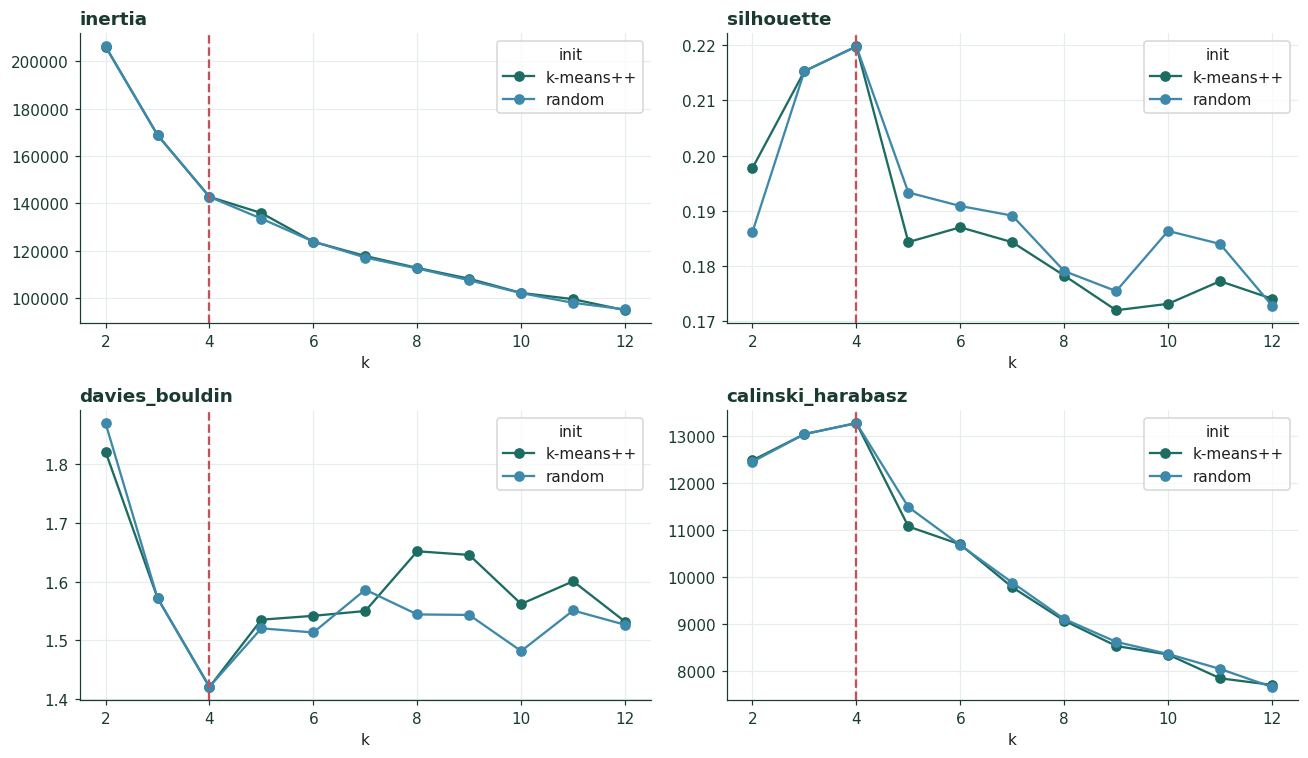

In [616]:
# best k = best average rank of silhouette (higher is better) and Davies-Bouldin (lower is better)
res["mean_rank"] = (res["silhouette"].rank(ascending=False) + res["davies_bouldin"].rank()) / 2
BEST_K = int(res.loc[res["mean_rank"].idxmin(), "k"])
print("best k:", BEST_K)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, metric in zip(axes.flat, ["inertia", "silhouette", "davies_bouldin", "calinski_harabasz"]):
    res.pivot(index="k", columns="init", values=metric).plot(ax=ax, marker="o", title=metric)
    ax.axvline(BEST_K, color=red, ls="--")
save("01_k_selection.png")

* Silhouette peaks at k = 4 (0.220)
* Davies–Bouldin is lowest at k = 4 (1.421)
* Calinski–Harabasz is highest at k = 4 (13,271) 
* Inertia: by eye the elbow is also k = 4

All metrics agree on k=4

## 6 baseline vs tuned

The final model is re-fit with the chosen configuration. Its clusters are then renumbered by size (C0 = largest), and the centroids are reordered the same way so that `predict` on the saved model returns the same numbering.

In [617]:
final = KMeans(n_clusters=BEST_K, init="k-means++", n_init=1, random_state=RANDOM_STATE).fit(X)

# renumber the clusters by size so that C0 is the largest
order = np.argsort(-np.bincount(final.labels_))            # old cluster ids, largest first
new_id = {old: new for new, old in enumerate(order)}
final.labels_ = np.array([new_id[old] for old in final.labels_])
final.cluster_centers_ = final.cluster_centers_[order]
labels = final.labels_
C = [f"C{k}" for k in range(BEST_K)]

tuned_scores = evaluate(final)
comparison = pd.DataFrame([baseline_scores, tuned_scores], index=["baseline", "tuned"])
comparison.loc["change"] = comparison.loc["tuned"] - comparison.loc["baseline"]
comparison.round(3)

,silhouette,davies_bouldin,calinski_harabasz,inertia
baseline,0.184,1.535,11070.558,135944.843
tuned,0.220,1.421,13270.688,142789.680
change,0.036,-0.114,2200.130,6844.837


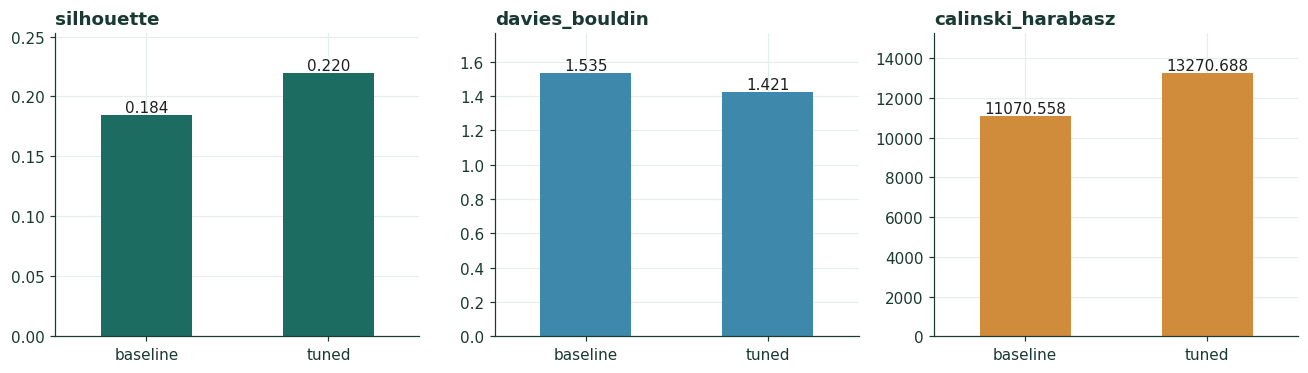

In [618]:
axes = comparison.loc[["baseline", "tuned"], ["silhouette", "davies_bouldin", "calinski_harabasz"]].plot.bar(
    subplots=True, layout=(1, 3), figsize=(12, 3.5), legend=False, rot=0)
for ax in axes.flat:
    fmt = "%.0f" if ax.get_title() == "calinski_harabasz" else "%.3f"
    ax.bar_label(ax.containers[0], fmt=fmt)     
    ax.margins(y=0.15)                          
save("02_baseline_vs_tuned.png")



* The tuned model is better on **silhouette, Davies–Bouldin and Calinski–Harabasz**.
* Inertia is higher for the tuned model, as expected: inertia always falls when k grows, so it cannot compare different k values (only the elbow shape was used)

## 7 Tuned clusters

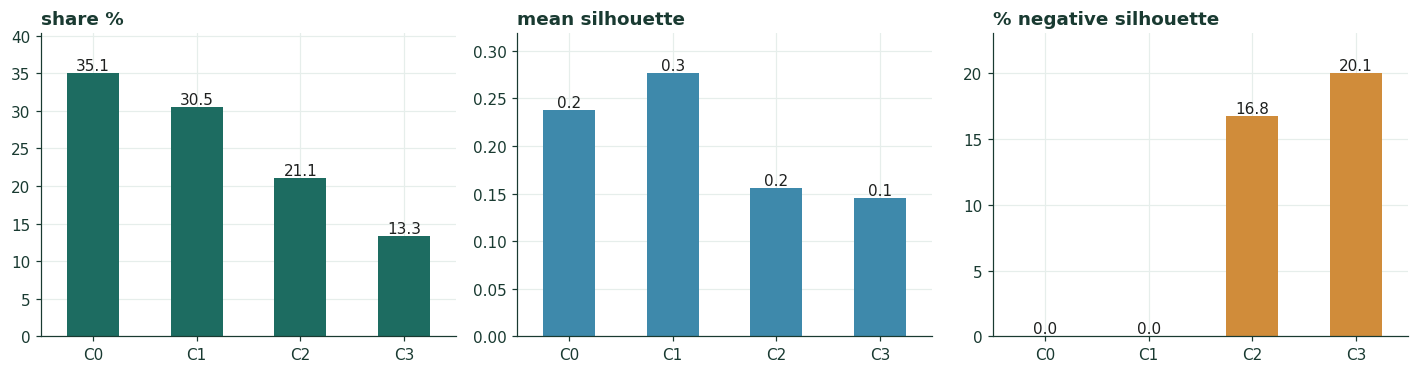

In [619]:
sil = silhouette_samples(X[S], labels[S])
per_cluster = pd.DataFrame({
    "share %": np.bincount(labels) / len(X) * 100,
    "mean silhouette": [sil[labels[S] == k].mean() for k in range(BEST_K)],
    "% negative silhouette": [(sil[labels[S] == k] < 0).mean() * 100 for k in range(BEST_K)],
}, index=C)

axes = per_cluster.plot.bar(subplots=True, layout=(1, 3), figsize=(13, 3.5), legend=False, rot=0)
for ax in axes.flat:
    fmt = "%.3f" if ax.get_title() == "mean silhouette" else "%.1f"
    ax.bar_label(ax.containers[0], fmt=fmt)     # value above each bar
    ax.margins(y=0.15)
save("03_sizes_silhouette.png")

In [620]:
g = info.groupby(labels)
prof = pd.DataFrame({
    "lead time (median days)": g["LeadTime"].median(),
    "nights (median)": g["TotalNights"].median(),
    "guests (mean)": g["TotalGuests"].mean(),
    "ADR (median)": g["ADR"].median(),
    "special requests (mean)": g["TotalOfSpecialRequests"].mean(),
    "repeat guests %": g["IsRepeatedGuest"].mean() * 100,
})
prof.index = C
prof.round(1)

,lead time (median days),nights (median),guests (mean),ADR (median),special requests (mean),repeat guests %
C0,68.0,3.0,2.0,105.6,1.4,0.5
C1,77.0,3.0,1.9,95.4,0.0,0.6
C2,4.0,1.0,1.5,97.0,0.5,11.1
C3,61.0,3.0,3.2,169.0,0.9,0.2


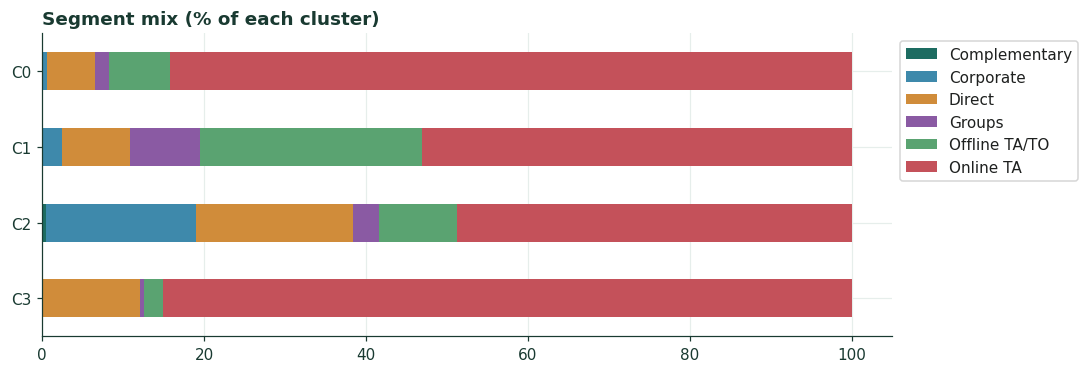

In [621]:
mix = pd.crosstab(labels, info["Segment"], normalize="index") * 100
mix.index = C
mix.plot.barh(stacked=True, figsize=(10, 3.5), title="Segment mix (% of each cluster)")
plt.gca().invert_yaxis()
plt.legend(bbox_to_anchor=(1, 1))
save("04_segment_mix.png")

## PCA

variance explained by PC1 + PC2: 0.575


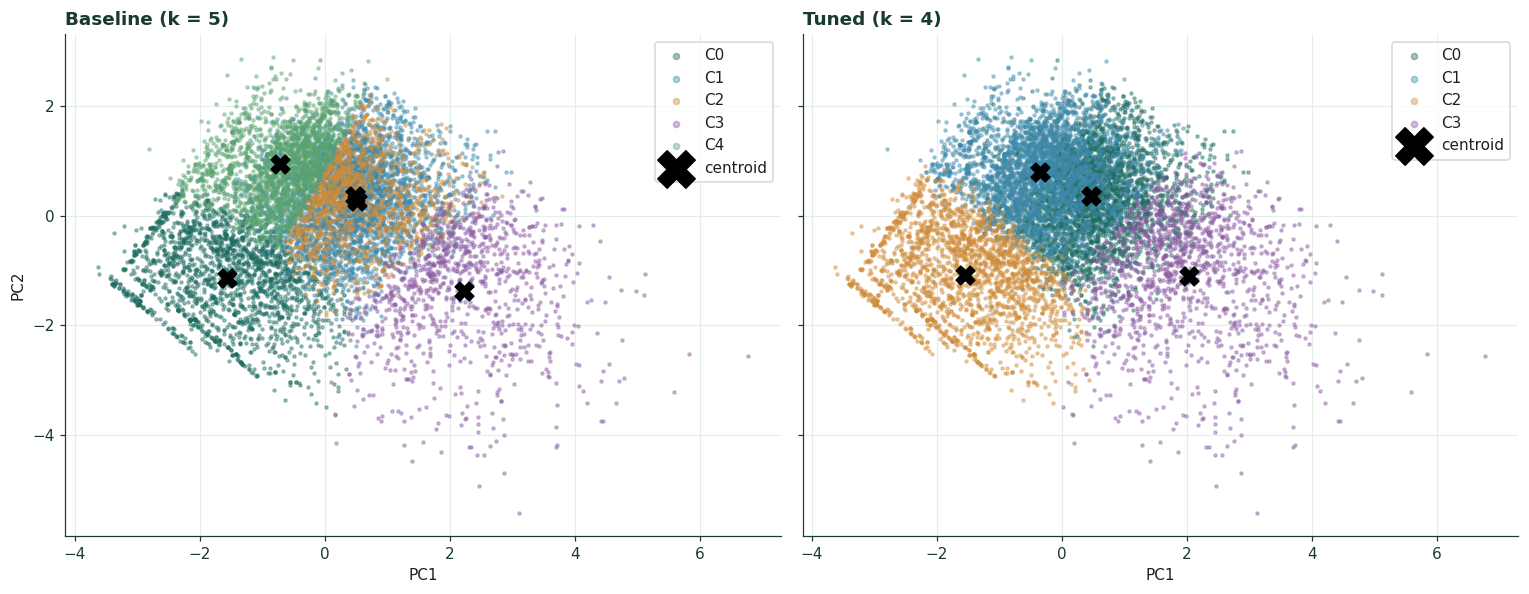

In [622]:
pca = PCA(n_components=2).fit(X)
P = pca.transform(X[S])
print("variance explained by PC1 + PC2:", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for ax, model, title in [(axes[0], baseline, "Baseline (k = 5)"), (axes[1], final, f"Tuned (k = {BEST_K})")]:
    for k in range(model.n_clusters):
        points = P[model.labels_[S] == k]
        ax.scatter(points[:, 0], points[:, 1], s=4, alpha=0.4, color=COLORS[k], label=f"C{k}")
    centers = pca.transform(model.cluster_centers_)
    ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=150, color="black", label="centroid")
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.legend(markerscale=2)
axes[0].set_ylabel("PC2")
save("05_pca_baseline_vs_tuned.png")

## 8 How the clusters differ from the average booking

Effect size = (cluster mean − overall mean) / overall standard deviation

We dont compare the means because features are on different scales. 
positive is above average for that features and vv

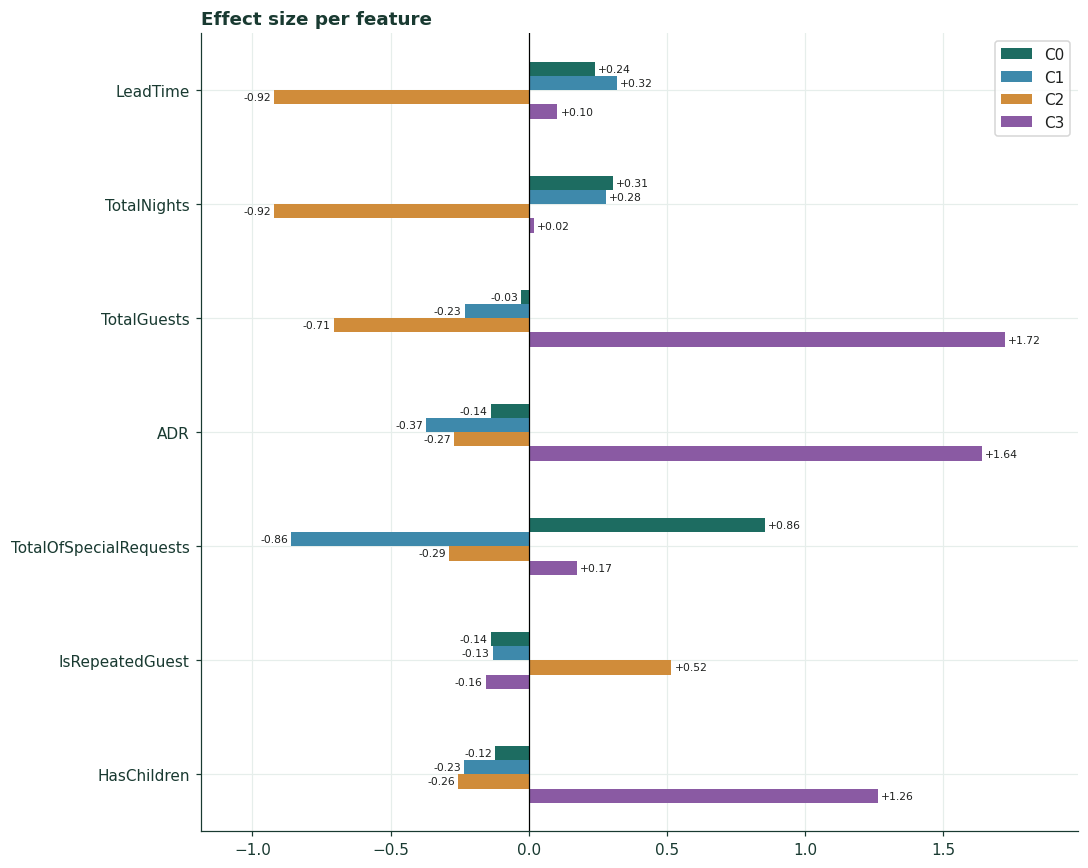

In [623]:
desc = info.copy()
desc["HasChildren"] = ((desc["Children"] + desc["Babies"]) > 0).astype(int)
feats = desc[["LeadTime", "TotalNights", "TotalGuests", "ADR", "TotalOfSpecialRequests", "IsRepeatedGuest", "HasChildren"]]

effect = (feats.groupby(labels).mean() - feats.mean()) / feats.std()
effect.index = C

ax = effect.T.plot.barh(figsize=(10, 8), title="Effect size per feature")
for bars in ax.containers:
    ax.bar_label(bars, fmt="%+.2f", fontsize=7, padding=2)   # value at the end of each bar
ax.margins(x=0.1)                                            # room for the labels
plt.axvline(0, color="black", lw=0.8)
plt.gca().invert_yaxis()
save("06_effect_sizes.png")

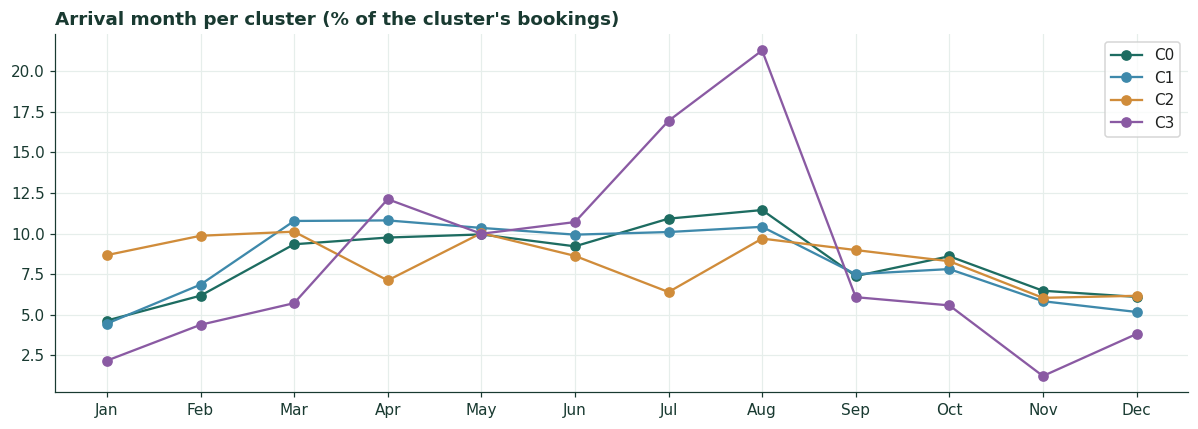

In [624]:
MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
season = pd.crosstab(desc["ArrivalDateMonth"], labels, normalize="columns").reindex(MONTHS) * 100
season.columns = C
season.index = [m[:3] for m in MONTHS]

season.plot(figsize=(11, 4), marker="o", title="Arrival month per cluster (% of the cluster's bookings)")
plt.xticks(range(12), season.index)
save("07_season_per_cluster.png")

### C0: Plan ahead guests (35%)
* The most special requests (1.4 on average)
* Mostly booked through Online TA, 2 guests, 3 nights, about 2 months ahead
* Silhouette 0.237, no negative values

### C1: Very plain agency bookings (31%)
* No special requests (0.0 on average)
* Lowest price (€95), booked furthest ahead (77 days)
* The most Offline TA/TO and Groups bookings
* Silhouette 0.277, no negative values (the cleanest cluster)


### C2: Last minute short stays (21%)
* Booked 4 days ahead for 1 night, 1.5 guests on average
* The only cluster with many repeat guests (11%), and the most Corporate and Direct bookings
* More arrivals in January–March and fewer in summer than the other clusters
* Silhouette 0.156, 16.8% negative

note: business and short-notice trips

### C3: Large parties (13%)
* 3.2 guests on average and the highest price (€169)
* Far more bookings with children than any other cluster, and a clear peak in July–August
* Silhouette 0.146, 20.1% negative (the loosest cluster)

note: family holidays in the summer

Children and arrival month were not used to build the clusters, but they still fit (families in summer, business trips off-season)

## 9 Leakage audit

`IsCanceled` was not an input and was not used to choose any hyperparameter. It is only used here, to check that the clusters are not just a split into "cancels" and "does not cancel" 

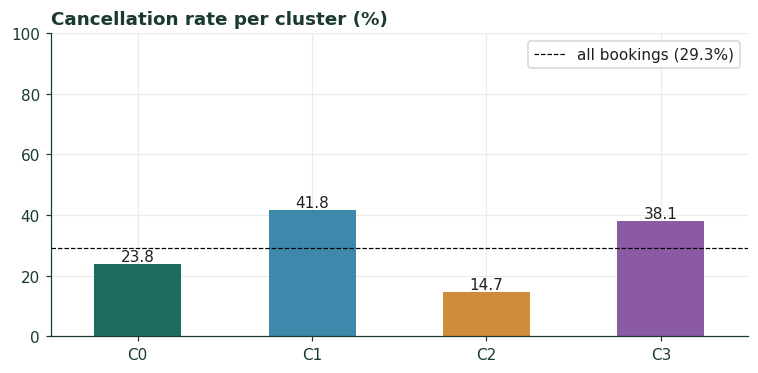

In [625]:
rate = info.groupby(labels)["IsCanceled"].mean() * 100
rate.index = C
overall = info["IsCanceled"].mean() * 100

ax = rate.plot.bar(figsize=(7, 3.5), rot=0, color=COLORS[:BEST_K], title="Cancellation rate per cluster (%)")
ax.bar_label(ax.containers[0], fmt="%.1f")     
ax.axhline(overall, color="black", ls="--", lw=0.8, label=f"all bookings ({overall:.1f}%)")
ax.set_ylim(0, 100)
ax.legend(handles=ax.lines)
save("08_cancellation.png")

Cancellation ranges from 14.7% (C2) to 41.8% (C1), around 29.3% for all bookings. No cluster is close to 0% or 100%, so the clusters are not a disguised cancellation split and nothing leaked into the inputs

## Save the tuned model

In [626]:
joblib.dump(final, f"{MODEL_DIR}/kmeans_tuned.joblib")

['model/kmeans_tuned.joblib']